![alt text](../../pythonexposed-high-resolution-logo-black.jpg "Optionele titel")

### Meervoudige Grafieken

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

We kunnen meerdere assen per figuur maken, in een rasterlay-out.

In [3]:
mpl.style.use('seaborn-v0_8-pastel')

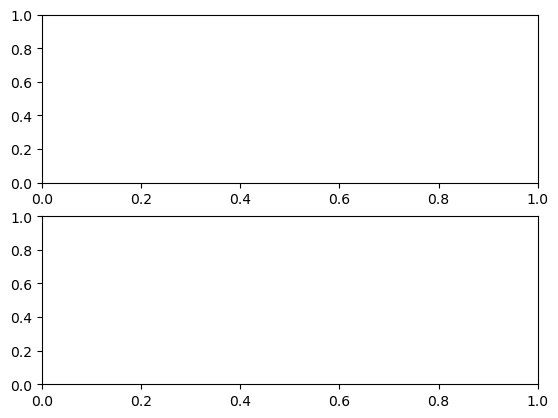

In [5]:
nrows = 2
ncols = 1
# je krijgt nog steeds een tuple terug: fig en axes.
# we hebben nu echter meerdere assen in 1 figuur!
fig, axes = plt.subplots(nrows, ncols)

De geretourneerde assen worden geretourneerd als een NumPy-array, op basis van het aantal rijen en kolommen dat is gespecificeerd bij het maken van de grafieken:

In [8]:
type(axes), axes # je krijg 2 axes objecten terug!

(numpy.ndarray, array([<Axes: >, <Axes: >], dtype=object))

array([<Axes: >, <Axes: >], dtype=object)

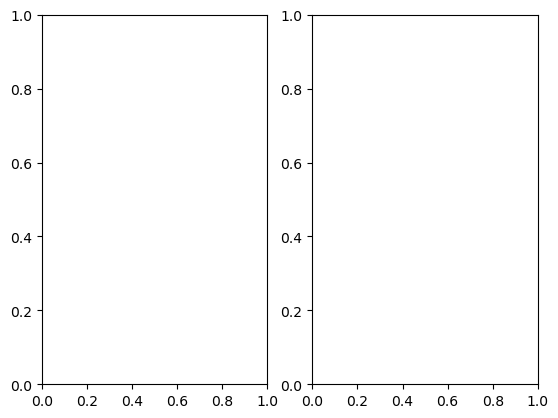

In [9]:
# we maken nu eens één rij en twee kolommen: 
fig, axs = plt.subplots(1, 2)
axs

array([[<Axes: >, <Axes: >],
       [<Axes: >, <Axes: >]], dtype=object)

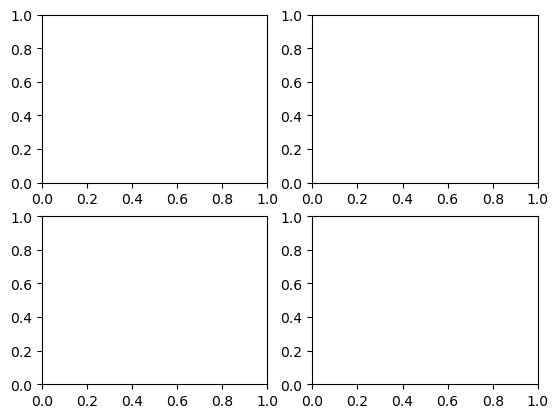

In [10]:
# of 2 maal 2 axes objecten:
fig, axs = plt.subplots(2, 2)
axs

De Axes objecten zitten in een NumPy array die dezelfde shape heeft als de assen op de figure.   

Soms is het makkelijker om de teruggegeven array uit te pakken:

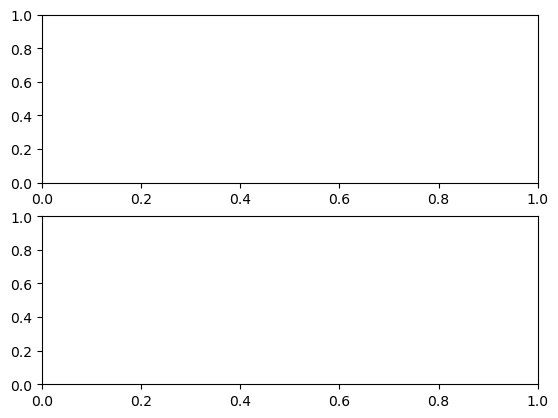

In [12]:
fig, (ax1, ax2) = plt.subplots(2, 1)

We kunnen dan plots toevoegen aan elk set assen zoals we eerder hebben gedaan:

In [13]:
x_axis = np.linspace(-2 * np.pi, 2 * np.pi, 200)

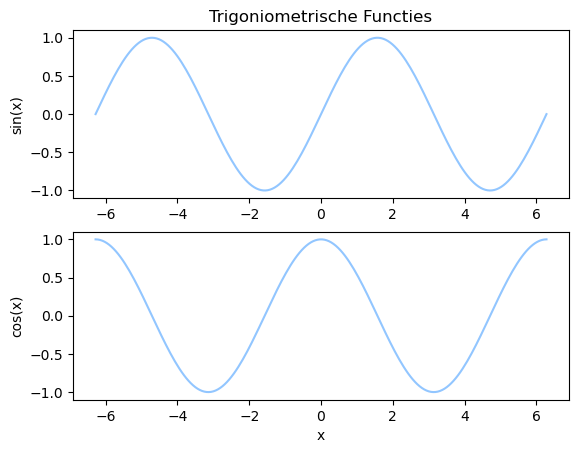

In [14]:
ax1.plot(x_axis, np.sin(x_axis), label='sin')
ax2.plot(x_axis, np.cos(x_axis), label='cos')
ax2.set_xlabel('x')
ax1.set_ylabel('sin(x)')
ax2.set_ylabel('cos(x)')
ax1.set_title('Trigoniometrische Functies')
fig

Je kan de grootte van de weergave als volgt aanpassen:

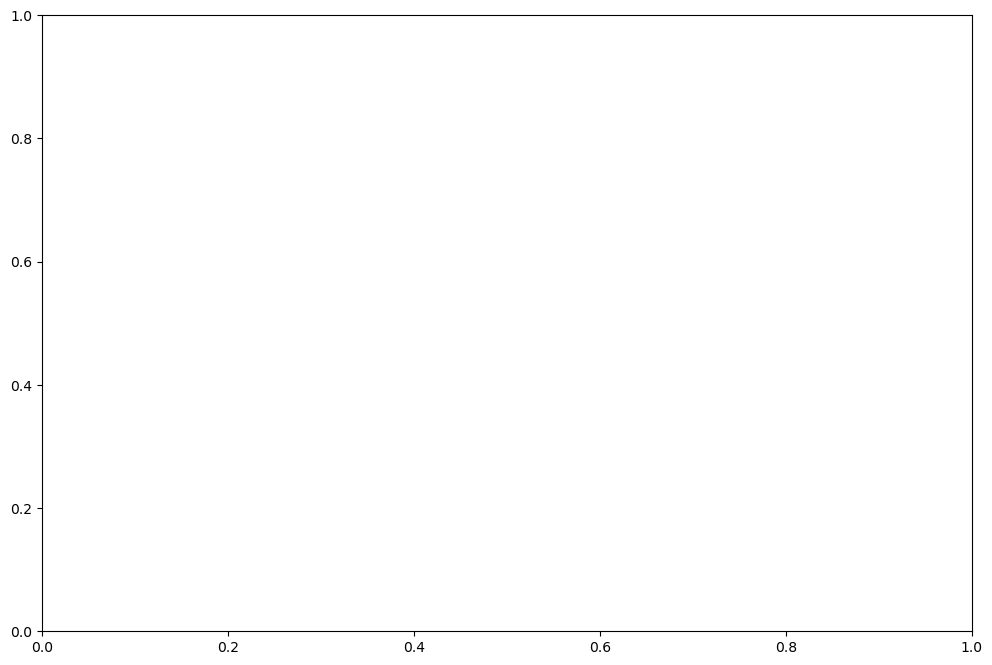

In [16]:
width = 12  
height = 8
fig, ax = plt.subplots(figsize=(width, height))

Als we willen dat deze grootte behouden blijft voor alle plots, kunnen we gewoon de standaard `figsize` wijzigen:

In [17]:
plt.rcParams['figure.figsize'] = [12, 8]

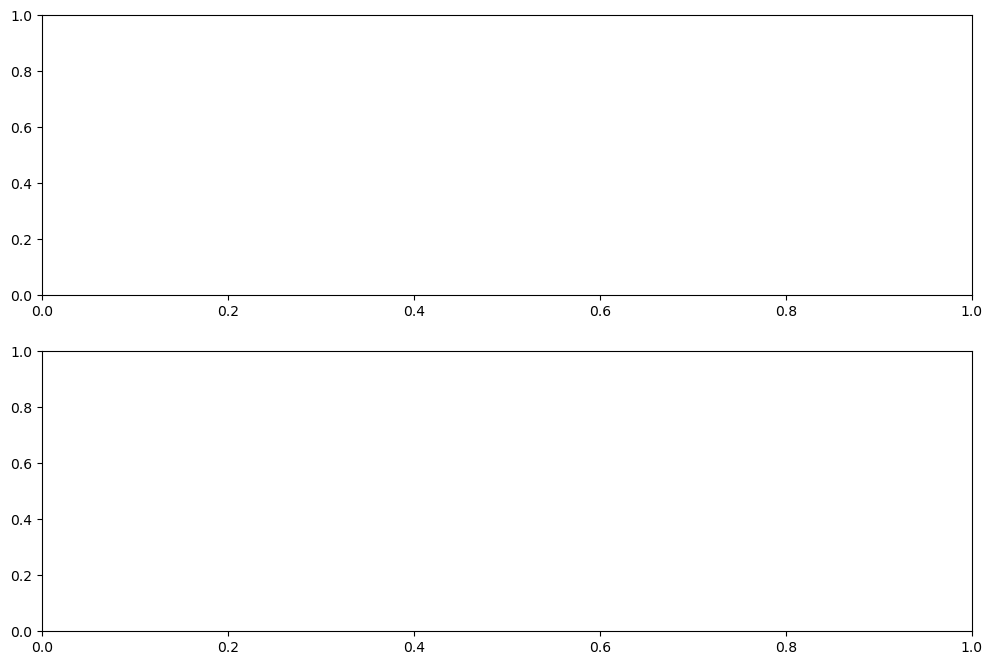

In [18]:
fig, (ax1, ax2) = plt.subplots(2, 1)

En we maken de grafiek opnieuw:

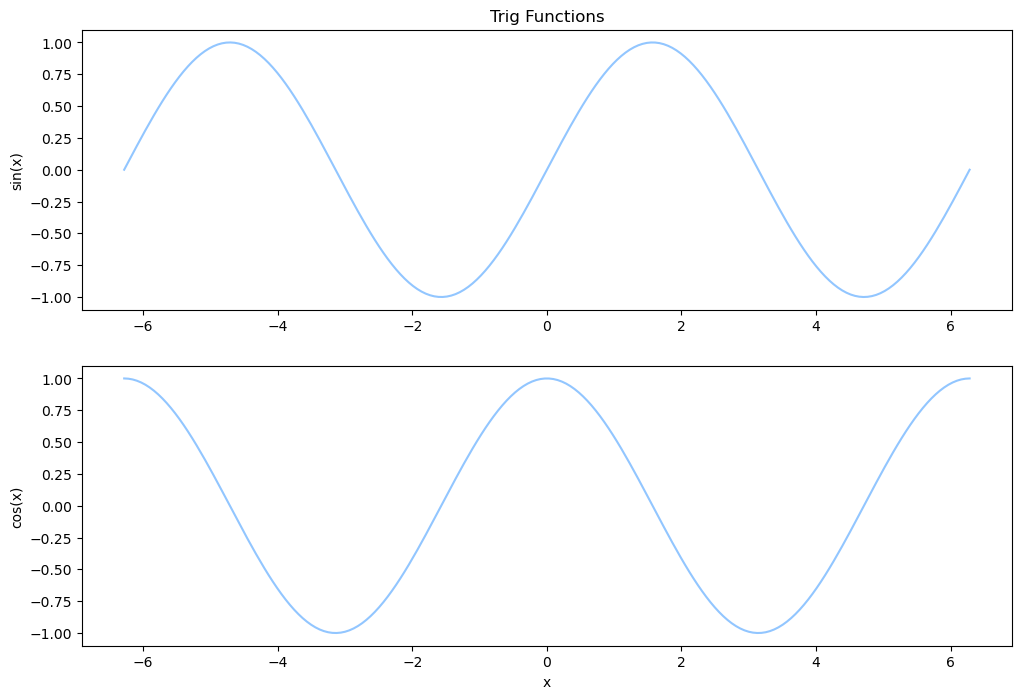

In [19]:
ax1.plot(x_axis, np.sin(x_axis), label='sin')
ax2.plot(x_axis, np.cos(x_axis), label='cos')
ax2.set_xlabel('x')
ax1.set_ylabel('sin(x)')
ax2.set_ylabel('cos(x)')
ax1.set_title('Trig Functions')
fig

Tot nu toe hebben we NumPy-arrays gebruikt om gegevens te maken voor grafieken, maar we kunnen ook arrays laden via Pandas.

In [20]:
df = pd.read_csv('DEXUSEU.csv')
df.iloc[:5, :]

,DATE,DEXUSEU
0,2015-04-03,1.0990
1,2015-04-06,1.1008
2,2015-04-07,1.0850
3,2015-04-08,1.0818
4,2015-04-09,1.0671


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1306 entries, 0 to 1305
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   DATE     1306 non-null   object
 1   DEXUSEU  1306 non-null   object
dtypes: object(2)
memory usage: 20.5+ KB


In [22]:
df.describe(include='all')

,DATE,DEXUSEU
count,1306,1306
unique,1306,787
top,2015-04-03,.
freq,1,55


Laten we eerst de DATUM kolom aanpakken - deze zijn geladen als strings:

In [17]:
df.iloc[0, 0], type(df.iloc[0, 0])

('2015-04-03', str)

Het eerste wat we zullen doen, is dat omzetten naar daadwerkelijke datums:

Ter info: in het geval van pd.to_datetime(df['DATE'], errors='coerce'), betekent het argument errors='coerce' dat als er parsingfouten worden gevonden tijdens het converteren van de data naar datetime objecten, deze fouten niet zullen resulteren in een error. In plaats daarvan worden de waarden die niet geparsed kunnen worden vervangen door NaT (Not a Time), wat staat voor een ontbrekende of niet-bestaande datum/tijd. Dit zorgt ervoor dat de conversieoperatie doorgaat zonder te worden onderbroken door fouten, en het helpt bij het omgaan met onvolledige of ongeldige datuminvoer.

In [23]:
pd.to_datetime(df['DATE'], errors='coerce')

0      2015-04-03
1      2015-04-06
2      2015-04-07
3      2015-04-08
4      2015-04-09
          ...    
1301   2020-03-30
1302   2020-03-31
1303   2020-04-01
1304   2020-04-02
1305   2020-04-03
Name: DATE, Length: 1306, dtype: datetime64[ns]

Dan moeten we ook de wisselkoersen omzetten naar floats.  We hebben enkele `.` punten in de data. Wanneer we de data omzetten naar floats, zal de `.` resulteren in `NaN`:

In [24]:
rates = pd.to_numeric(df['DEXUSEU'], errors='coerce')
rates

0       1.0990
1       1.1008
2       1.0850
3       1.0818
4       1.0671
         ...  
1301    1.1018
1302    1.1016
1303    1.0934
1304    1.0862
1305    1.0797
Name: DEXUSEU, Length: 1306, dtype: float64

Nu hebben we `NaN`-gegevens in onze wisselkoersen:

In [20]:
rates[rates.isnull()]

36     NaN
65     NaN
111    NaN
136    NaN
158    NaN
169    NaN
190    NaN
195    NaN
206    NaN
226    NaN
301    NaN
326    NaN
371    NaN
396    NaN
420    NaN
429    NaN
451    NaN
456    NaN
466    NaN
470    NaN
491    NaN
561    NaN
587    NaN
631    NaN
656    NaN
680    NaN
689    NaN
711    NaN
716    NaN
726    NaN
751    NaN
821    NaN
848    NaN
891    NaN
916    NaN
941    NaN
949    NaN
958    NaN
971    NaN
972    NaN
977    NaN
986    NaN
991    NaN
1011   NaN
1013   NaN
1081   NaN
1109   NaN
1151   NaN
1181   NaN
1201   NaN
1214   NaN
1233   NaN
1238   NaN
1251   NaN
1271   NaN
Name: DEXUSEU, dtype: float64

We zouden de rijen met `NaN` kunnen verwijderen, maar hier kies ik ervoor om lineaire interpolatie te gebruiken om de ontbrekende waarden in te vullen:

In [21]:
rates.interpolate(method='linear')

0       1.0990
1       1.1008
2       1.0850
3       1.0818
4       1.0671
         ...  
1301    1.1018
1302    1.1016
1303    1.0934
1304    1.0862
1305    1.0797
Name: DEXUSEU, Length: 1306, dtype: float64

Laten we onze nieuwe dataset opbouwen:

In [25]:
data = pd.concat(
    [
        pd.to_datetime(df['DATE'], errors='coerce'),
        pd.to_numeric(
            df['DEXUSEU'], errors='coerce'
        ).interpolate(method='linear')
    ],
    axis=1
)
data[:5]

,DATE,DEXUSEU
0,2015-04-03,1.0990
1,2015-04-06,1.1008
2,2015-04-07,1.0850
3,2015-04-08,1.0818
4,2015-04-09,1.0671


In [26]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1306 entries, 0 to 1305
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   DATE     1306 non-null   datetime64[ns]
 1   DEXUSEU  1306 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 20.5 KB


We willen de wisselkoers in een grafiek weergeven. Matplotlib werkt niet altijd goed met Pandas-series, dus we moeten onze reeks converteren naar reguliere NumPy-arrays voordat we de gegevens plotten (we gebruiken het attribuut `.values`):

In [27]:
data['DATE'].values

array(['2015-04-03T00:00:00.000000000', '2015-04-06T00:00:00.000000000',
       '2015-04-07T00:00:00.000000000', ...,
       '2020-04-01T00:00:00.000000000', '2020-04-02T00:00:00.000000000',
       '2020-04-03T00:00:00.000000000'], dtype='datetime64[ns]')

In [28]:
data['DEXUSEU'].values

array([1.099 , 1.1008, 1.085 , ..., 1.0934, 1.0862, 1.0797])

Text(0.5, 1.0, 'US/EU Exchange Rate')

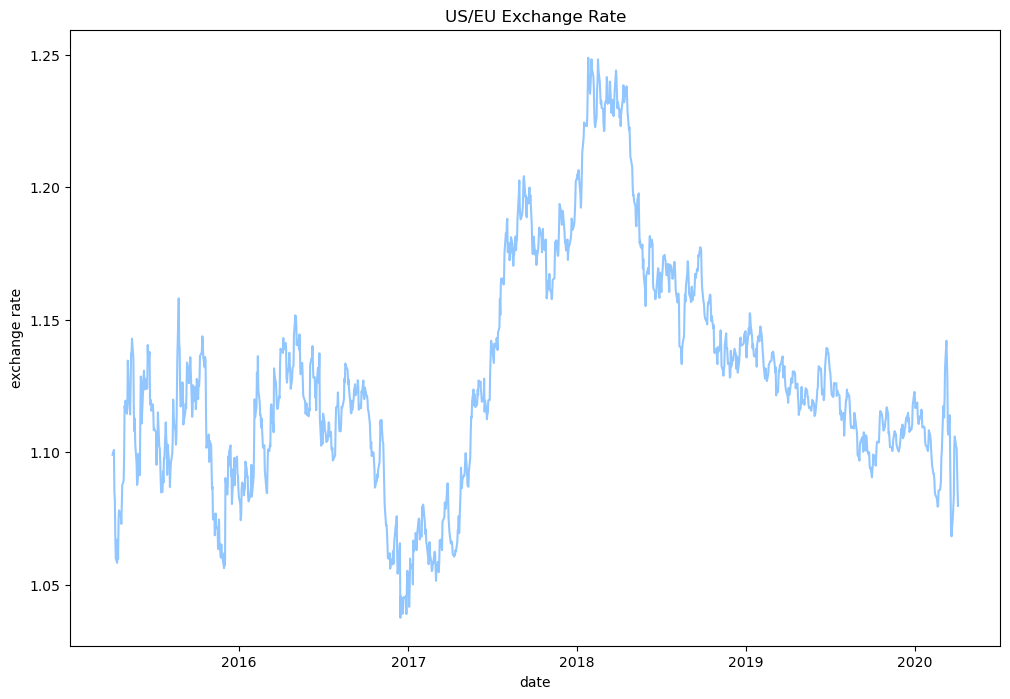

In [29]:
fig, ax = plt.subplots()
ax.plot(data['DATE'].values, data['DEXUSEU'].values, label='rate')
ax.set_xlabel('date')
ax.set_ylabel('exchange rate')
ax.set_title('US/EU Exchange Rate')

We gaan nu een voortschrijdend gemiddelde aan de gegevens toevoegen en dat op dezelfde grafiek weergeven.

Pandas heeft een `.rolling()` methode die gegevens groepeert in een rollend venster, en we kunnen vervolgens het gemiddelde berekenen in elk venster:

In [30]:
m5_avg = data['DEXUSEU'].rolling(window=5).mean()
m5_avg

0           NaN
1           NaN
2           NaN
3           NaN
4       1.08674
         ...   
1301    1.09462
1302    1.09906
1303    1.10104
1304    1.09778
1305    1.09254
Name: DEXUSEU, Length: 1306, dtype: float64

Text(0.5, 1.0, 'US/EU Exchange Rate')

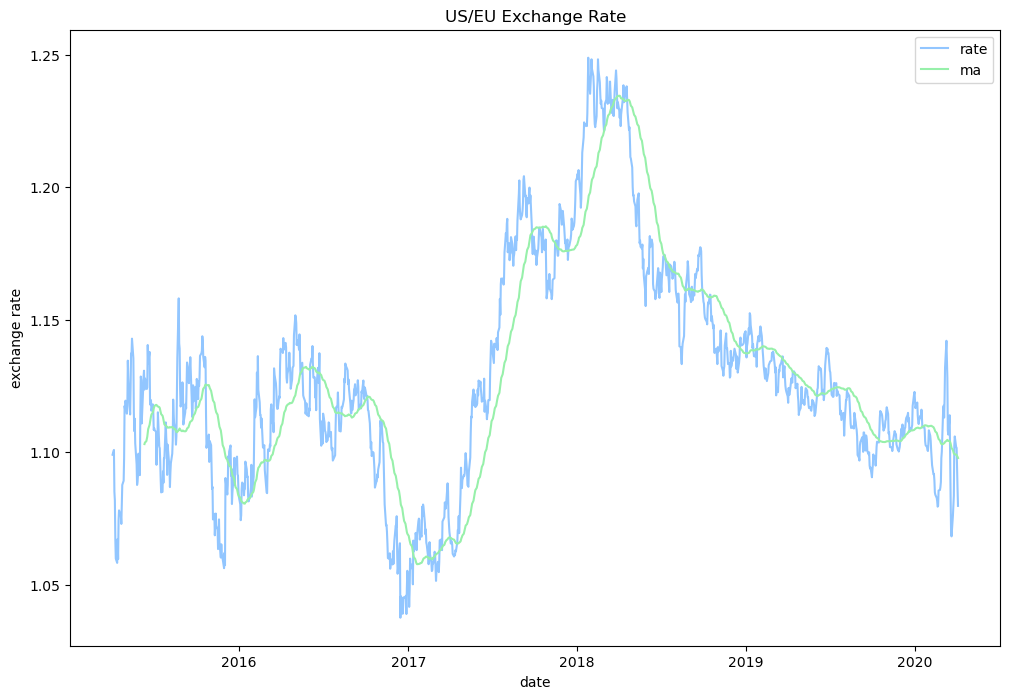

In [31]:
fig, ax = plt.subplots()
ax.plot(
    data['DATE'].values, 
    data['DEXUSEU'].values, 
    label='rate'
)
ax.plot(
    data['DATE'].values, 
    data['DEXUSEU'].rolling(window=50).mean(), 
    label='ma'
)
ax.set_xlabel('date')
ax.set_ylabel('exchange rate')
ax.legend()
ax.set_title('US/EU Exchange Rate')

(als je je afvraagt waarom we die `Text(...)` regel boven onze grafiek zien, dat is Jupyter die het laatste resultaat afdrukt (wat het instellen van de titel was):

In [29]:
ax.set_title('US/EU Exchange Rate')

Text(0.5, 1.0, 'US/EU Exchange Rate')

Een eenvoudige manier om deze uitvoer niet weer te geven, is simpelweg ervoor te zorgen dat Jupyter het resultaat van die laatste `set_title`-aanroep niet afdrukt. Dat kunnen we doen door Jupyter iets anders te laten afdrukken, zoals `None`:

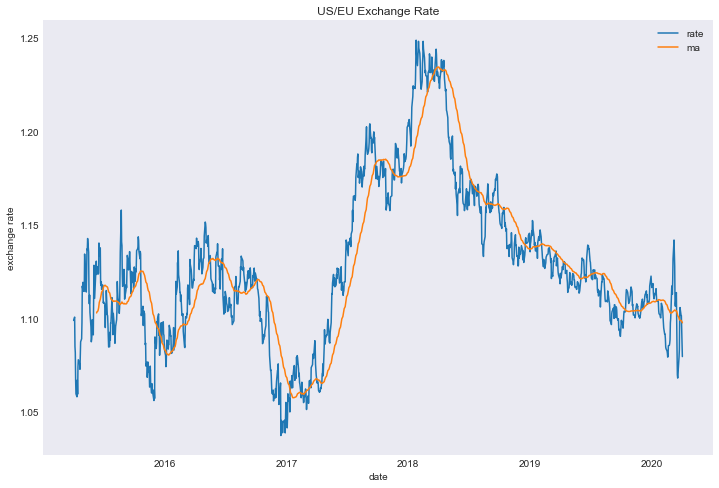

In [30]:
fig, ax = plt.subplots()
ax.plot(
    data['DATE'].values, 
    data['DEXUSEU'].values, 
    label='rate'
)
ax.plot(
    data['DATE'].values, 
    data['DEXUSEU'].rolling(window=50).mean(), 
    label='ma'
)
ax.set_xlabel('date')
ax.set_ylabel('exchange rate')
ax.legend()
ax.set_title('US/EU Exchange Rate')
None

We zouden ook een secundaire grafiek onder de hoofdgrafiek kunnen toevoegen:

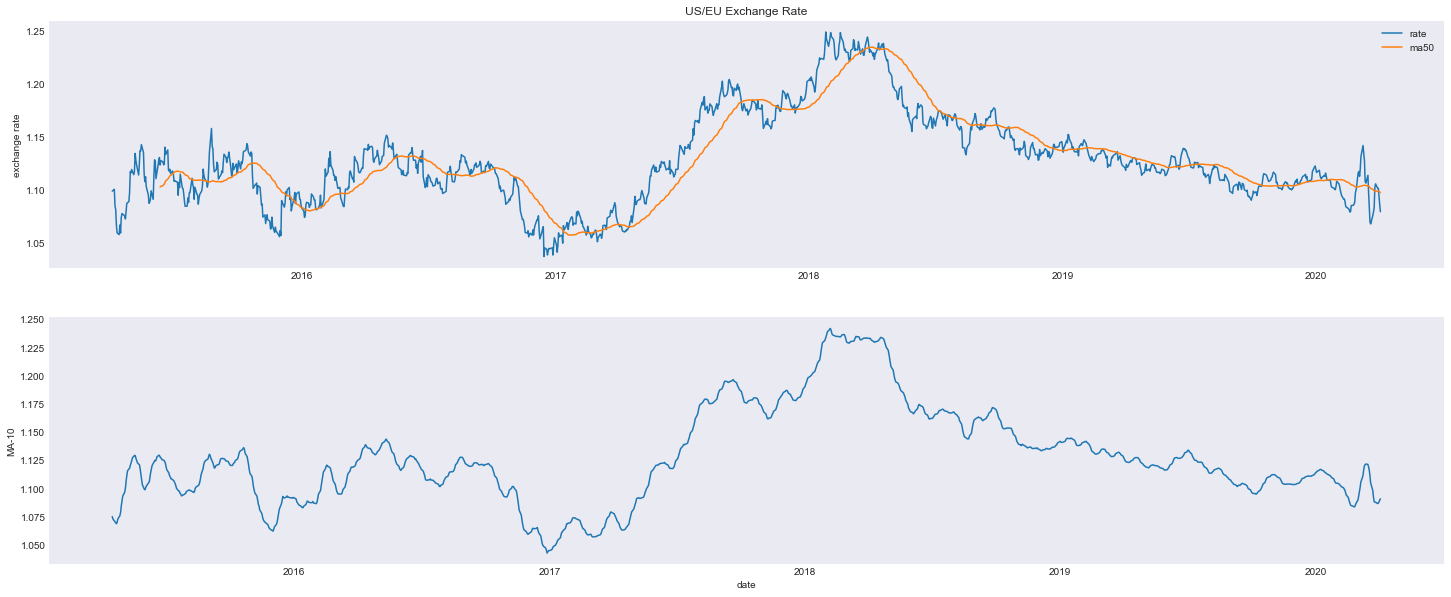

In [31]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(25, 10))
ax1.plot(
    data['DATE'].values,
    data['DEXUSEU'].values,
    label='rate',
)
ax1.plot(
    data['DATE'].values,
    data['DEXUSEU'].rolling(window=50).mean(),
    label='ma50'
)
ax2.plot(
    data['DATE'].values,
    data['DEXUSEU'].rolling(window=10).mean(),
    label='ma10'
)
ax2.set_xlabel('date')
ax1.set_ylabel('exchange rate')
ax2.set_ylabel('MA-10')
ax1.set_title('US/EU Exchange Rate')
ax1.legend()

None